In [1]:
from pathlib import Path
import joblib

PROJECT_DIR = (
    Path.home()
    / "Downloads"
    / "IDX-Exchange-Data-Science"
)

modeling_data = joblib.load(
    PROJECT_DIR / "week3_modeling_data.joblib"
)

X_train_encoded = modeling_data["X_train"]
X_test_encoded = modeling_data["X_test"]
y_train = modeling_data["y_train"]
y_test = modeling_data["y_test"]
preprocessor = modeling_data["preprocessor"]

print("Training shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)

Training shape: (297161, 17310)
Test shape: (12488, 17310)


In [2]:
#linear regression model

In [3]:
from sklearn.linear_model import LinearRegression

# Train linear regression using the encoded training data.
linear_model = LinearRegression()
linear_model.fit(X_train_encoded, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](17310,)","[-0., 0.,-0.,..., 0., 0., 0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.29e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,17310


In [4]:
from sklearn.metrics import r2_score

# Predict close prices for the test set.
y_test_pred = linear_model.predict(X_test_encoded)

# Evaluate test-set R².
test_r2 = r2_score(y_test, y_test_pred)

print(f"Linear Regression — Test R²: {test_r2:.4f}")

Linear Regression — Test R²: -0.0003


In [5]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Scale features while preserving the sparse format.
scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

# Retrain linear regression on scaled data.
scaled_linear_model = LinearRegression()
scaled_linear_model.fit(X_train_scaled, y_train)

# Check training fit first.
scaled_train_pred = scaled_linear_model.predict(X_train_scaled)
scaled_train_r2 = r2_score(y_train, scaled_train_pred)

print(f"Scaled training R²: {scaled_train_r2:.4f}")

Scaled training R²: 0.1865


In [6]:
# Evaluate the scaled model on the test set.
scaled_test_pred = scaled_linear_model.predict(X_test_scaled)
scaled_test_r2 = r2_score(y_test, scaled_test_pred)

print(f"Scaled training R²: {scaled_train_r2:.4f}")
print(f"Scaled test R²: {scaled_test_r2:.4f}")

Scaled training R²: 0.1865
Scaled test R²: 0.0117


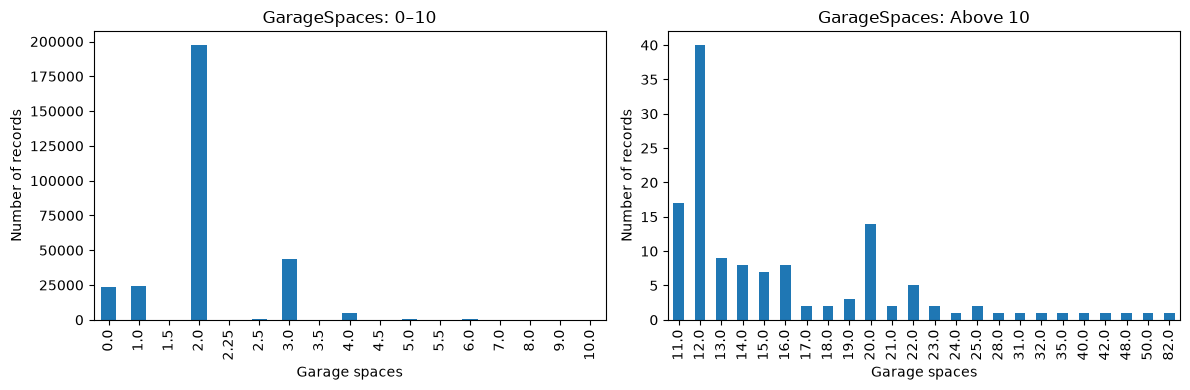

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load garage counts from the cleaned training dataset.
garage = pd.read_csv(
    PROJECT_DIR / "single_family_train_cleaned.csv",
    usecols=["GarageSpaces"],
)["GarageSpaces"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Show the main distribution.
garage.loc[garage.between(0, 10)].value_counts().sort_index().plot.bar(
    ax=axes[0]
)
axes[0].set_title("GarageSpaces: 0–10")
axes[0].set_xlabel("Garage spaces")
axes[0].set_ylabel("Number of records")

# Inspect the upper tail.
garage.loc[garage.gt(10)].value_counts().sort_index().plot.bar(
    ax=axes[1]
)
axes[1].set_title("GarageSpaces: Above 10")
axes[1].set_xlabel("Garage spaces")
axes[1].set_ylabel("Number of records")

plt.tight_layout()
plt.show()